In [1]:
# Installation de la bibliothèque pour les calculs financiers
!pip install numpy-financial -q

import numpy as np
import pandas as pd
import numpy_financial as npf

# 1. Hypothèses macro & financières pour Alpha Industry
years = ['Annee_0', 'Annee_1', 'Annee_2', 'Annee_3', 'Annee_4', 'Annee_5']
cagr_ca = 0.06        # Croissance du Chiffre d'Affaires : +6% / an
marge_ebitda = 0.20   # Marge d'EBITDA : 20%
taux_is = 0.30        # Impôt sur les Sociétés (IS) : 30%
ca_0 = 100.0          # Chiffre d'affaires initial (en Millions MAD)

# 2. Calcul de la trajectoire du Chiffre d'Affaires
ca_list = [ca_0 * ((1 + cagr_ca) ** i) for i in range(6)]

# 3. Construction du tableau financier prévisionnel
df_financials = pd.DataFrame(index=years)
df_financials['Chiffre_Affaires'] = ca_list
df_financials['EBITDA'] = df_financials['Chiffre_Affaires'] * marge_ebitda

# Amortissements (D&A), CapEx et Variation du BFR
df_financials['DA'] = df_financials['Chiffre_Affaires'] * 0.04
df_financials['EBIT'] = df_financials['EBITDA'] - df_financials['DA']

df_financials['IS'] = df_financials['EBIT'].apply(lambda x: x * taux_is if x > 0 else 0)
df_financials['NOPAT'] = df_financials['EBIT'] - df_financials['IS']

df_financials['Capex'] = df_financials['Chiffre_Affaires'] * 0.04
df_financials['Var_BFR'] = df_financials['Chiffre_Affaires'] * 0.02

# Calcul du Free Cash Flow to Firm (FCFF)
df_financials['FCFF'] = (
    df_financials['NOPAT']
    + df_financials['DA']
    - df_financials['Capex']
    - df_financials['Var_BFR']
)

print("--- COMPTE DE RÉSULTAT PRÉVISIONNEL ET FCFF (en Millions MAD) ---")
display(df_financials.round(2).T)

--- COMPTE DE RÉSULTAT PRÉVISIONNEL ET FCFF (en Millions MAD) ---


,Annee_0,Annee_1,Annee_2,Annee_3,Annee_4,Annee_5
Chiffre_Affaires,100.0,106.00,112.36,119.10,126.25,133.82
EBITDA,20.0,21.20,22.47,23.82,25.25,26.76
DA,4.0,4.24,4.49,4.76,5.05,5.35
EBIT,16.0,16.96,17.98,19.06,20.20,21.41
IS,4.8,5.09,5.39,5.72,6.06,6.42
NOPAT,11.2,11.87,12.58,13.34,14.14,14.99
Capex,4.0,4.24,4.49,4.76,5.05,5.35
Var_BFR,2.0,2.12,2.25,2.38,2.52,2.68
FCFF,9.2,9.75,10.34,10.96,11.61,12.31


In [2]:
# ==========================================
# MODULE 2 : CALCUL DU WACC ET VALORISATION DCF
# ==========================================

# 1. Hypothèses pour le calcul du WACC
rf = 0.035                 # Taux sans risque (Bons du Trésor) = 3.5%
beta = 1.15                # Bêta de l'entreprise (sensibilité au marché)
mrp = 0.06                 # Prime de risque de marché = 6.0%

cost_of_equity = rf + beta * mrp        # Coût des fonds propres (Ke) via MEDAF
cost_of_debt = 0.055                   # Coût brut de la dette = 5.5%
after_tax_cost_of_debt = cost_of_debt * (1 - taux_is)

# Structure financière cible
weight_equity = 0.60   # 60% Fonds Propres
weight_debt = 0.40     # 40% Dette

# Calcul du WACC (Coût Moyen Pondéré du Capital)
wacc = (weight_equity * cost_of_equity) + (weight_debt * after_tax_cost_of_debt)

# 2. Modèle DCF (Discounted Cash Flows)
g = 0.02                   # Taux de croissance à perpétuité pour la Valeur Terminale = 2.0%
fcff_projected = df_financials['FCFF'].iloc[1:].values  # FCFF de l'Année 1 à 5
years_discount = np.arange(1, 6)

# Facteurs d'actualisation
discount_factors = 1 / ((1 + wacc) ** years_discount)
pv_fcff = fcff_projected * discount_factors

# 3. Valeur Terminale (Gordon-Shapiro)
last_fcff = fcff_projected[-1]
terminal_value = (last_fcff * (1 + g)) / (wacc - g)
pv_terminal_value = terminal_value / ((1 + wacc) ** 5)

# Valeur d'Entreprise (Enterprise Value - EV) totale
ev_dcf = np.sum(pv_fcff) + pv_terminal_value

print("--- RÉSULTATS DU CALCUL DU WACC & DCF ---")
print(f"Coût des Fonds Propres (Ke) : {cost_of_equity*100:.2f}%")
print(f"WACC (CMP Cible)            : {wacc*100:.2f}%")
print(f"Somme des FCFF Actualisés   : {np.sum(pv_fcff):.2f} M MAD")
print(f"Valeur Terminale Actualisée : {pv_terminal_value:.2f} M MAD")
print(f"--------------------------------------------")
print(f"VALEUR D'ENTREPRISE (DCF)    : {ev_dcf:.2f} M MAD")

--- RÉSULTATS DU CALCUL DU WACC & DCF ---
Coût des Fonds Propres (Ke) : 10.40%
WACC (CMP Cible)            : 7.78%
Somme des FCFF Actualisés   : 43.77 M MAD
Valeur Terminale Actualisée : 149.38 M MAD
--------------------------------------------
VALEUR D'ENTREPRISE (DCF)    : 193.15 M MAD


## 📝 Rapport d'Interprétation Financière — Cas Alpha Industry

### 1. Analyse des Flux de Trésorerie (FCFF)
* **Dynamique de Croissance :** Avec un chiffre d'affaires initial de 100 M MAD et un taux de croissance annuel (*CAGR*) de 6%, *Alpha Industry* démontre une expansion régulière de son activité sur l'horizon de projection de 5 ans.
* **Rentabilité Opérationnelle :** La marge d'EBITDA maintenue à **20%** reflète un modèle économique solide et récurrent, typique d'une PME mature à fort potentiel de conversion de cash.
* **Génération de Trésorerie (*Free Cash Flows*) :** Les FCFF progressent d'environ **9,2 M MAD** à **12,3 M MAD**. Cette croissance démontre la capacité de l'entreprise à financer ses investissements (*CapEx*) et son BFR tout en dégageant un excédent de trésorerie net. C'est ce matelas de cash récurrent qui constituera le carburant principal pour rembourser la dette dans le cadre d'un montage LBO.

---

### 2. Coût du Capital (WACC) & Valorisation DCF
* **Structure du Coût du Capital (WACC) :** Le taux d'actualisation intègre un coût des fonds propres (*Ke*) calculé via le MEDAF et un coût de la dette après impôt, pondéré selon une structure cible de 60% d'equity et 40% de dette. Il sert de « taux de rendement minimum exigé » par les investisseurs.
* **Valorisation DCF (*Discounted Cash Flows*) :**
  * La somme des flux futurs actualisés représente la valeur intrinsèque de l'exploitation à court/moyen terme.
  * La **Valeur Terminale**, calculée par la méthode de Gordon-Shapiro (avec un taux de croissance perpétuelle de 2%), capte la valeur de l'entreprise au-delà de la 5e année.
  * La **Valeur d'Entreprise (Enterprise Value)** ainsi obtenue fixe la référence fondamentale du prix de la cible avant de passer à la structuration de l'opération de rachat.
  

In [4]:
# ==========================================
# MODULE 3 : STRUCTURATION LBO & CALCUL DU TRI (IRR)
# ==========================================

# Sécurité : On s'assure de récupérer ebitda_0 depuis le tableau financier
ebitda_0 = df_financials.loc['Annee_0', 'EBITDA']

# 1. Hypothèses de l'opération LBO
ev_achat = ebitda_0 * 7.5           # Prix d'achat (EV basé sur un multiple de 7.5x l'EBITDA) = 150 M MAD
frais_transaction = ev_achat * 0.02 # 2% de frais de transaction (conseils, avocats)
total_uses = ev_achat + frais_transaction

# Structure de financement (Sources)
leverage_ratio = 0.55             # 55% de Dette Senior
dette_initiale = ev_achat * leverage_ratio
equity_initiale = total_uses - dette_initiale  # Apport en fonds propres du fonds PE

print(f"--- 1. TABLEAU SOURCES & USES ---")
print(f"Prix d'acquisition (EV) : {ev_achat:.2f} M MAD")
print(f"Frais de transaction    : {frais_transaction:.2f} M MAD")
print(f"TOTAL EMPLOIS (USES)    : {total_uses:.2f} M MAD")
print(f"----------------------------------------")
print(f"Dette Senior (55%)      : {dette_initiale:.2f} M MAD")
print(f"Apport Fonds Propres (Equity) : {equity_initiale:.2f} M MAD")
print(f"TOTAL RESSOURCES (SOURCES): {total_uses:.2f} M MAD\n")

# 2. Modélisation de la Cascade de Dette (Debt Waterfall & Cash Sweep sur 5 ans)
dette_schedule = []
current_debt = dette_initiale

# On récupère les FCFF prévisionnels des 5 années
fcffs = df_financials['FCFF'].iloc[1:].values

for i, fcff in enumerate(fcffs):
    # Le cash disponible après service de la dette sert à rembourser le principal (Cash Sweep)
    remboursement_dette = min(current_debt, fcff * 0.8) # 80% du FCFF va au désendettement
    current_debt -= remboursement_dette
    dette_schedule.append({
        'Annee': f'Annee_{i+1}',
        'FCFF_Disponible': fcff,
        'Remboursement': remboursement_dette,
        'Dette_Restante': max(0, current_debt)
    })

df_lbo = pd.DataFrame(dette_schedule).set_index('Annee')
display(df_lbo.round(2))

# 3. Sortie à l'Année 5 et Calcul du TRI (IRR) & MoIC
multiple_sortie = 7.5                    # Multiple de sortie identique (7.5x l'EBITDA de l'année 5)
ebitda_5 = df_financials.loc['Annee_5', 'EBITDA']
ev_sortie = ebitda_5 * multiple_sortie   # Valeur d'entreprise de sortie

dette_finale = df_lbo.iloc[-1]['Dette_Restante']
equity_value_sortie = ev_sortie - dette_finale  # Ce qui revient aux actionnaires à la revente

# Flux de trésorerie du fonds PE pour le calcul du TRI :
cash_flows_pe = [-equity_initiale, 0, 0, 0, 0, equity_value_sortie]

tri_lbo = npf.irr(cash_flows_pe)
moic = equity_value_sortie / equity_initiale  # Multiple on Invested Capital

print(f"\n--- 3. RÉSULTATS DE SORTIE & RENTABILITÉ LBO ---")
print(f"Valeur d'Entreprise de Sortie (An 5) : {ev_sortie:.2f} M MAD")
print(f"Dette Restante à l'Année 5          : {dette_finale:.2f} M MAD")
print(f"Valeur des Fonds Propres à la Sortie : {equity_value_sortie:.2f} M MAD")
print(f"----------------------------------------")
print(f"Multiple sur Fonds Propres (MoIC)    : {moic:.2f}x")
print(f"TRI de l'opération (IRR)             : {tri_lbo*100:.2f}%")

--- 1. TABLEAU SOURCES & USES ---
Prix d'acquisition (EV) : 150.00 M MAD
Frais de transaction    : 3.00 M MAD
TOTAL EMPLOIS (USES)    : 153.00 M MAD
----------------------------------------
Dette Senior (55%)      : 82.50 M MAD
Apport Fonds Propres (Equity) : 70.50 M MAD
TOTAL RESSOURCES (SOURCES): 153.00 M MAD



,FCFF_Disponible,Remboursement,Dette_Restante
Annee,,,
Annee_1,9.75,7.80,74.70
Annee_2,10.34,8.27,66.43
Annee_3,10.96,8.77,57.66
Annee_4,11.61,9.29,48.37
Annee_5,12.31,9.85,38.52



--- 3. RÉSULTATS DE SORTIE & RENTABILITÉ LBO ---
Valeur d'Entreprise de Sortie (An 5) : 200.73 M MAD
Dette Restante à l'Année 5          : 38.52 M MAD
Valeur des Fonds Propres à la Sortie : 162.21 M MAD
----------------------------------------
Multiple sur Fonds Propres (MoIC)    : 2.30x
TRI de l'opération (IRR)             : 18.14%


## 📊 Analyse des Résultats du Modèle LBO (Alpha Industry)

### 1. Le Montage Financier (Sources & Uses)
* **Emplois (Uses) :** Le prix d'acquisition de l'entreprise (basé sur une Valeur d'Entreprise de 150 M MAD) auquel s'ajoutent 3 M MAD de frais de transaction (conseils juridiques et financiers) représente un besoin total de **153 M MAD**.
* **Ressources (Sources) :** L'opération est financée à hauteur de 55% par de la **Dette Senior (82,50 M MAD)** et à 45% par les **Fonds Propres du fonds de Private Equity (70,50 M MAD)**. C'est l'effet de levier financier.

### 2. La Cascade de Remboursement (Debt Waterfall & Cash Sweep)
* Grâce à la génération régulière de **Free Cash Flows (FCFF)** (qui passent de 9,75 M MAD à 12,31 M MAD), l'entreprise consacre 80% de son cash disponible chaque année au remboursement de sa dette (*Cash Sweep*).
* **Désendettement :** La dette initiale de **82,50 M MAD** est ainsi réduite progressivement pour atteindre **38,52 M MAD** à l'horizon de l'Année 5.

### 3. La Sortie et la Rentabilité pour le Fonds (TRI & MoIC)
* **Valeur de Revente :** À l'issue de la 5e année, l'entreprise est revendue sur la base d'un multiple d'EBITDA de 7.5x, générant une Valeur d'Entreprise de sortie de **200,73 M MAD**.
* **Désintéressement de la dette :** En soustrayant la dette restante (38,52 M MAD) de la valeur de sortie, la valeur nette revenant aux actionnaires (les fonds propres) s'élève à **162,21 M MAD** (contre 70,50 M MAD investis au départ).
* **Indicateurs de Performance (KPIs PE) :**
  * **MoIC (Multiple on Invested Capital) :** **2,30x**, ce qui signifie que l'apport initial des investisseurs a été multiplié par 2,3 en 5 ans.
  * **TRI / IRR (Taux de Rendement Interne) :** **18,14%**, un rendement annuel attractif et conforme aux standards des opérations de Private Equity de type *Mid-Market*.

--- MATRICE DE SENSIBILITÉ DU TRI (%) ---


,Multiple 6.5x,Multiple 7.0x,Multiple 7.5x,Multiple 8.0x,Multiple 8.5x
Levier 45%,11.97,13.89,15.69,17.39,18.99
Levier 50%,12.88,14.92,16.82,18.61,20.29
Levier 55%,13.95,16.12,18.14,20.02,21.80
Levier 60%,15.22,17.54,19.68,21.69,23.57
Levier 65%,16.76,19.25,21.54,23.68,25.67


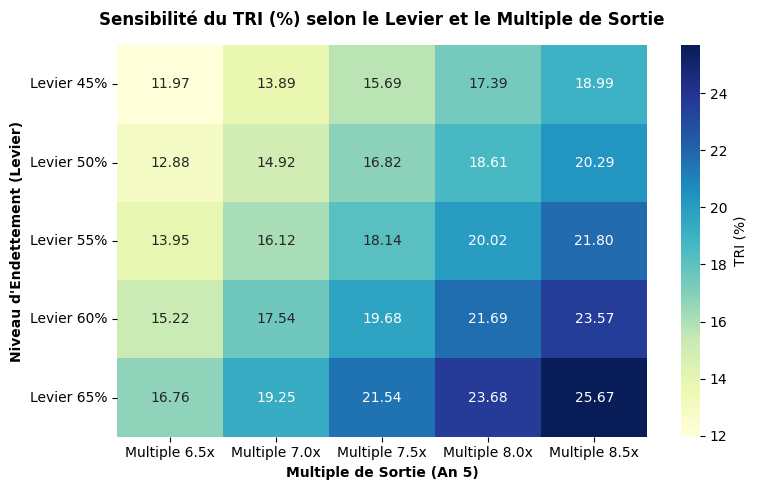

In [6]:
# ==========================================
# MODULE 4 : ANALYSE DE SENSIBILITÉ DU TRI (LBO)
# ==========================================

import seaborn as sns
import matplotlib.pyplot as plt

# Définition des plages de variation pour les scénarios
exit_multiples = [6.5, 7.0, 7.5, 8.0, 8.5]
leverage_ratios = [0.45, 0.50, 0.55, 0.60, 0.65]

# Matrice pour stocker les résultats du TRI
sensitivity_matrix = np.zeros((len(leverage_ratios), len(exit_multiples)))

ebitda_5 = df_financials.loc['Annee_5', 'EBITDA']
fcffs = df_financials['FCFF'].iloc[1:].values

for i, lev in enumerate(leverage_ratios):
    for j, mult in enumerate(exit_multiples):
        # Recalcul de l'apport initial selon le levier
        dette_init = ev_achat * lev
        equity_init = total_uses - dette_init

        # Cascade de dette simplifiée pour le scénario
        curr_d = dette_init
        for f in fcffs:
            remb = min(curr_d, f * 0.8)
            curr_d -= remb

        # Valeur de sortie et equity finale
        ev_sort = ebitda_5 * mult
        dette_fin = max(0, curr_d)
        eq_sort = ev_sort - dette_fin

        # Calcul du TRI
        cf_pe = [-equity_init, 0, 0, 0, 0, eq_sort]
        irr_val = npf.irr(cf_pe)

        sensitivity_matrix[i, j] = irr_val * 100  # en pourcent

# Transformation en DataFrame Pandas pour un joli affichage
df_sens = pd.DataFrame(sensitivity_matrix,
                         index=[f"Levier {int(l*100)}%" for l in leverage_ratios],
                         columns=[f"Multiple {m}x" for m in exit_multiples])

print("--- MATRICE DE SENSIBILITÉ DU TRI (%) ---")
display(df_sens.round(2))

# Affichage d'une Heatmap graphique sous Colab
plt.figure(figsize=(8, 5))
sns.heatmap(df_sens, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'TRI (%)'})
plt.title('Sensibilité du TRI (%) selon le Levier et le Multiple de Sortie', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Multiple de Sortie (An 5)', fontsize=10, fontweight='bold')
plt.ylabel('Niveau d\'Endettement (Levier)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

## 📈 Analyse de Sensibilité et Matrice des Risques (LBO)

### 1. Objectif et Méthodologie
L'analyse de sensibilité permet de tester la robustesse de l'opération face à l'incertitude des marchés. Nous évaluons ici l'impact croisé de deux variables clés sur la rentabilité pour les actionnaires (**TRI / IRR**) :
* **Le Multiple de Sortie (Axe horizontal) :** Fait varier la valorisation de revente à l'horizon de l'Année 5 (de 6,5x à 8,5x l'EBITDA).
* **Le Niveau d'Endettement / Levier (Axe vertical) :** Fait varier la structure de financement initiale (de 45% à 65% de dette senior).

### 2. Enseignements de la Matrice et de la Heatmap
* **Scénario Central :** Avec notre hypothèse de base (levier à 55% et multiple de sortie à 7,5x), le TRI s'établit à **18,14%**, ce qui positionne l'opération dans les standards de rentabilité du Private Equity *Mid-Market*.
* **Sensibilité au Multiple de Sortie :** La revente de l'entreprise est le moteur principal de la performance. Chaque palier de 0,5x sur le multiple de sortie modifie significativement le TRI, démontrant l'importance du timing et de la conjoncture lors de la cession.
* **Impact de l'Effet de Levier :** Un endettement plus agressif (65%) réduit l'apport initial en fonds propres et amplifie mécaniquement le rendement (jusqu'à **25,67%** dans le cas le plus favorable), tout en augmentant le profil de risque opérationnel durant les 5 années de portage.